# Nexora Care Flow: Feature Engineering

# Import Libraries and Load the Clean Data

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

In [7]:
df = pd.read_csv("../data/AppointmentRecords_clean.csv", parse_dates=["AppointmentDateTime", "Date"])
df.shape

(129352, 17)

# Daily Appointment Volume per Clinic

In [8]:
daily = df.groupby(["ClinicID", "ClinicName", "Date"]).size().reset_index(name="Appointments")
daily = daily.sort_values(["ClinicID", "Date"]).reset_index(drop=True)
daily.head()

,ClinicID,ClinicName,Date,Appointments
0,1,Nexora Care - Riverside,2024-01-01,13
1,1,Nexora Care - Riverside,2024-01-02,75
2,1,Nexora Care - Riverside,2024-01-03,66
3,1,Nexora Care - Riverside,2024-01-04,62
4,1,Nexora Care - Riverside,2024-01-05,36


In [9]:
daily.shape

(2457, 4)

In [10]:
daily["Appointments"].sum()

np.int64(129352)

In [11]:
daily["Appointments"].sum()

np.int64(129352)

In [12]:
daily.duplicated(subset=["ClinicID", "Date"]).sum()

np.int64(0)

# Lag and Rolling Features

In [13]:
for k in [7, 14, 28]:
    lagged = daily[["ClinicID", "Date", "Appointments"]].copy()
    lagged["Date"] = lagged["Date"] + pd.Timedelta(days=k)
    lagged = lagged.rename(columns={"Appointments": f"Lag{k}"})
    daily = daily.merge(lagged, on=["ClinicID", "Date"], how="left")

In [14]:
roll = (daily.set_index("Date")
             .groupby("ClinicID")["Appointments"]
             .rolling("28D").mean()
             .rename("Roll28")
             .reset_index())
roll["Date"] = roll["Date"] + pd.Timedelta(days=7)
daily = daily.merge(roll, on=["ClinicID", "Date"], how="left")

In [15]:
daily.shape

(2457, 8)

In [16]:
daily.isnull().sum()

ClinicID          0
ClinicName        0
Date              0
Appointments      0
Lag7             25
Lag14            50
Lag28           100
Roll28           25
dtype: int64

In [17]:
daily[daily["ClinicID"] == 1].head(10)

,ClinicID,ClinicName,Date,Appointments,Lag7,Lag14,Lag28,Roll28
0,1,Nexora Care - Riverside,2024-01-01,13,NaN,NaN,NaN,NaN
1,1,Nexora Care - Riverside,2024-01-02,75,NaN,NaN,NaN,NaN
2,1,Nexora Care - Riverside,2024-01-03,66,NaN,NaN,NaN,NaN
3,1,Nexora Care - Riverside,2024-01-04,62,NaN,NaN,NaN,NaN
4,1,Nexora Care - Riverside,2024-01-05,36,NaN,NaN,NaN,NaN
5,1,Nexora Care - Riverside,2024-01-06,17,NaN,NaN,NaN,NaN
6,1,Nexora Care - Riverside,2024-01-08,55,13.0,NaN,NaN,13.000000
7,1,Nexora Care - Riverside,2024-01-09,52,75.0,NaN,NaN,44.000000
8,1,Nexora Care - Riverside,2024-01-10,72,66.0,NaN,NaN,51.333333
9,1,Nexora Care - Riverside,2024-01-11,71,62.0,NaN,NaN,54.000000


# Calendar and Holiday Indicators

In [18]:
df.groupby("Date")["SeasonFlag"].nunique().max()

np.int64(1)

In [19]:
date_info = df.groupby("Date").agg(
    IsHoliday=("IsHoliday", "max"),
    SeasonFlag=("SeasonFlag", "first"),
).reset_index()
daily = daily.merge(date_info, on="Date", how="left")

In [20]:
holiday_dates = date_info.loc[date_info["IsHoliday"], "Date"]
daily["DayAfterHoliday"] = (daily["Date"] - pd.Timedelta(days=1)).isin(holiday_dates) & ~daily["IsHoliday"]
daily["DayOfWeek"] = daily["Date"].dt.dayofweek
daily["Month"] = daily["Date"].dt.month
daily["IsFluSeason"] = (daily["SeasonFlag"] == "Flu Season").astype(int)
daily["IsHoliday"] = daily["IsHoliday"].astype(int)
daily["DayAfterHoliday"] = daily["DayAfterHoliday"].astype(int)
daily["DaysSinceStart"] = (daily["Date"] - daily["Date"].min()).dt.days
daily.head()

,ClinicID,ClinicName,Date,Appointments,Lag7,Lag14,Lag28,Roll28,IsHoliday,SeasonFlag,DayAfterHoliday,DayOfWeek,Month,IsFluSeason,DaysSinceStart
0,1,Nexora Care - Riverside,2024-01-01,13,NaN,NaN,NaN,NaN,1,Flu Season,0,0,1,1,0
1,1,Nexora Care - Riverside,2024-01-02,75,NaN,NaN,NaN,NaN,0,Flu Season,1,1,1,1,1
2,1,Nexora Care - Riverside,2024-01-03,66,NaN,NaN,NaN,NaN,0,Flu Season,0,2,1,1,2
3,1,Nexora Care - Riverside,2024-01-04,62,NaN,NaN,NaN,NaN,0,Flu Season,0,3,1,1,3
4,1,Nexora Care - Riverside,2024-01-05,36,NaN,NaN,NaN,NaN,0,Flu Season,0,4,1,1,4


In [21]:
daily.isnull().sum()

ClinicID             0
ClinicName           0
Date                 0
Appointments         0
Lag7                25
Lag14               50
Lag28              100
Roll28              25
IsHoliday            0
SeasonFlag           0
DayAfterHoliday      0
DayOfWeek            0
Month                0
IsFluSeason          0
DaysSinceStart       0
dtype: int64

In [22]:
daily[["IsHoliday", "DayAfterHoliday", "IsFluSeason"]].sum()

IsHoliday           99
DayAfterHoliday     75
IsFluSeason        597
dtype: int64

# Time-Ordered Train and Test Split

In [23]:
split_date = pd.Timestamp("2025-10-01")
train = daily[daily["Date"] < split_date].copy()
test = daily[daily["Date"] >= split_date].copy()
train.shape, test.shape

((2128, 15), (329, 15))

In [24]:
train["Date"].max(), test["Date"].min()

(Timestamp('2025-09-30 00:00:00'), Timestamp('2025-10-01 00:00:00'))

In [25]:
test[["Lag7", "Lag14", "Lag28", "Roll28"]].isnull().sum()

Lag7      0
Lag14     0
Lag28     0
Roll28    0
dtype: int64

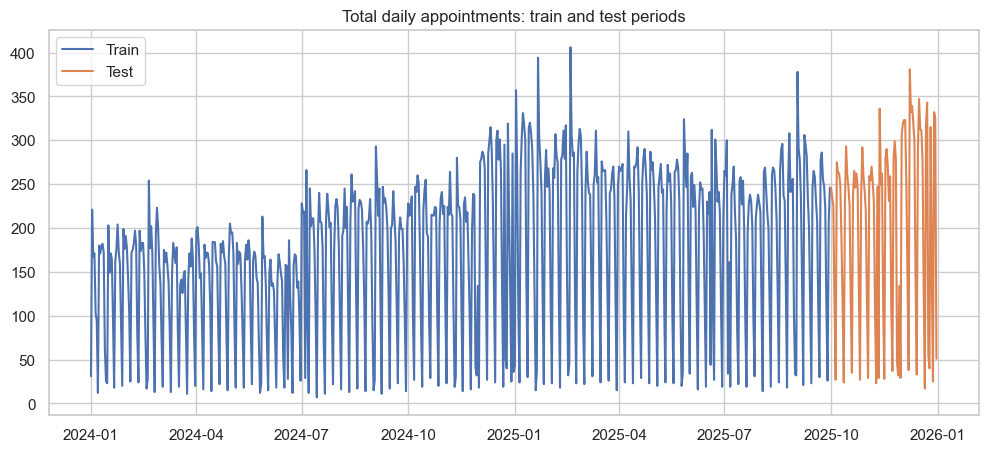

In [26]:
total = daily.groupby("Date")["Appointments"].sum()
plt.plot(total[total.index < split_date], label="Train")
plt.plot(total[total.index >= split_date], label="Test")
plt.title("Total daily appointments: train and test periods")
plt.legend()
plt.show()

# Naive Baseline

In [28]:
def mape(actual, pred):
    return (abs(actual - pred) / actual).mean() * 100

def rmse(actual, pred):
    return (((actual - pred) ** 2).mean()) ** 0.5

In [29]:
test["Baseline"] = test["Lag28"]
mape(test["Appointments"], test["Baseline"]), rmse(test["Appointments"], test["Baseline"])

(np.float64(60.58839782623123), np.float64(23.207993068105655))

In [30]:
for name, g in test.groupby("ClinicName"):
    print(name, round(mape(g["Appointments"], g["Baseline"]), 1), round(rmse(g["Appointments"], g["Baseline"]), 1))

Nexora Care - Downtown Express 61.2 16.6
Nexora Care - Hillcrest 45.3 23.6
Nexora Care - Lakeside 62.5 29.7
Nexora Care - Riverside 73.2 21.9


# Gradient Boosting Model

In [31]:
from sklearn.ensemble import HistGradientBoostingRegressor

features = ["ClinicID", "DayOfWeek", "Month", "IsHoliday", "DayAfterHoliday",
            "IsFluSeason", "DaysSinceStart", "Lag7", "Lag14", "Lag28", "Roll28"]

model = HistGradientBoostingRegressor(categorical_features=["ClinicID", "DayOfWeek"], random_state=42)
model.fit(train[features], train["Appointments"])

,loss,'squared_error'
,quantile,None
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,"['ClinicID', 'DayOfWeek']"


In [32]:
test["Predicted"] = model.predict(test[features])
results = pd.DataFrame({
    "Model": ["Naive baseline", "Gradient boosting"],
    "MAPE %": [mape(test["Appointments"], test["Baseline"]), mape(test["Appointments"], test["Predicted"])],
    "RMSE": [rmse(test["Appointments"], test["Baseline"]), rmse(test["Appointments"], test["Predicted"])],
}).round(2)
results

,Model,MAPE %,RMSE
0,Naive baseline,60.59,23.21
1,Gradient boosting,17.85,11.60


In [33]:
def score(d):
    return pd.Series({
        "Rows": len(d),
        "Baseline MAPE %": mape(d["Appointments"], d["Baseline"]),
        "Model MAPE %": mape(d["Appointments"], d["Predicted"]),
        "Baseline RMSE": rmse(d["Appointments"], d["Baseline"]),
        "Model RMSE": rmse(d["Appointments"], d["Predicted"]),
    })

normal_days = test[(test["IsHoliday"] == 0) & (test["DayAfterHoliday"] == 0)]
holiday_days = test[(test["IsHoliday"] == 1) | (test["DayAfterHoliday"] == 1)]
pd.DataFrame({"All": score(test), "Normal days": score(normal_days),
              "Holiday and day after": score(holiday_days)}).round(2)

,All,Normal days,Holiday and day after
Rows,329.00,293.00,36.00
Baseline MAPE %,60.59,20.13,389.85
Model MAPE %,17.85,15.14,39.97
Baseline RMSE,23.21,16.84,51.13
Model RMSE,11.60,11.92,8.60


In [34]:
rows = {name: score(g) for name, g in test.groupby("ClinicName")}
pd.DataFrame(rows).T.round(2)

,Rows,Baseline MAPE %,Model MAPE %,Baseline RMSE,Model RMSE
Nexora Care - Downtown Express,92.0,61.24,19.53,16.64,8.84
Nexora Care - Hillcrest,79.0,45.34,15.62,23.59,12.83
Nexora Care - Lakeside,79.0,62.51,14.42,29.73,13.55
Nexora Care - Riverside,79.0,73.16,21.57,21.91,11.00


In [35]:
mape(test["Appointments"], test["Lag7"]), rmse(test["Appointments"], test["Lag7"])

(np.float64(62.200956156012055), np.float64(23.566564847754204))

In [36]:
test["AbsError"] = (test["Appointments"] - test["Predicted"]).abs()
test.sort_values("AbsError", ascending=False)[
    ["ClinicName", "Date", "Appointments", "Baseline", "Predicted", "IsHoliday", "DayAfterHoliday"]].head(10)

,ClinicName,Date,Appointments,Baseline,Predicted,IsHoliday,DayAfterHoliday
1233,Nexora Care - Lakeside,2025-12-08,135,75.0,84.357340,0,0
606,Nexora Care - Riverside,2025-12-08,99,65.0,57.606135,0,0
1246,Nexora Care - Lakeside,2025-12-23,134,91.0,94.142934,0,0
2439,Nexora Care - Hillcrest,2025-12-11,126,79.0,87.864764,0,0
1234,Nexora Care - Lakeside,2025-12-09,125,10.0,88.067796,0,0
2448,Nexora Care - Hillcrest,2025-12-22,103,92.0,74.093589,0,0
1211,Nexora Care - Lakeside,2025-11-12,76,85.0,104.809262,0,1
2442,Nexora Care - Hillcrest,2025-12-15,105,99.0,76.886755,0,0
1251,Nexora Care - Lakeside,2025-12-29,112,96.0,84.470805,0,0
2418,Nexora Care - Hillcrest,2025-11-17,99,73.0,72.592046,0,0


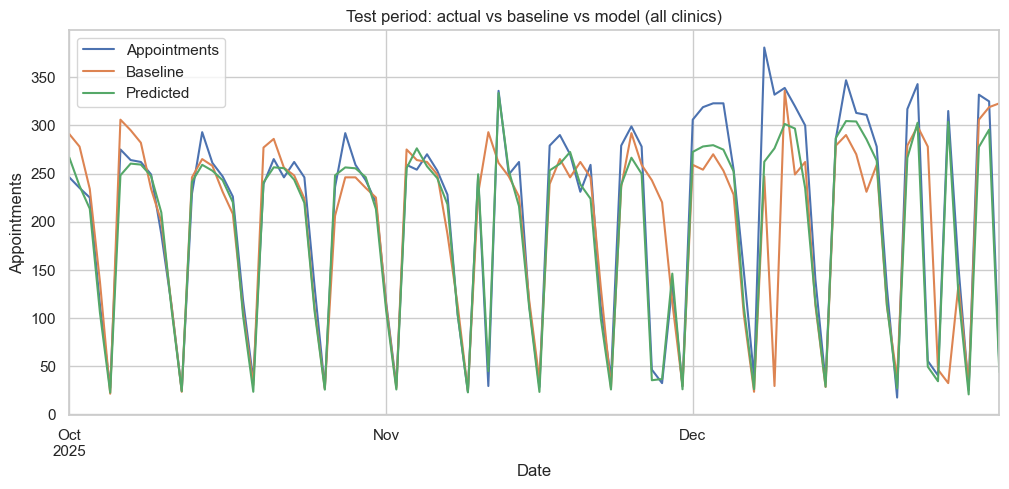

In [37]:
tot = test.groupby("Date")[["Appointments", "Baseline", "Predicted"]].sum()
tot.plot()
plt.title("Test period: actual vs baseline vs model (all clinics)")
plt.ylabel("Appointments")
plt.show()

In [38]:
daily["Split"] = np.where(daily["Date"] < split_date, "train", "test")
daily.shape

(2457, 16)

In [39]:
daily.to_csv("../outputs/features_daily.csv", index=False)

# Bias Check

In [40]:
test["Error"] = test["Predicted"] - test["Appointments"]
test["Error"].mean()

np.float64(-4.052681965486613)

In [41]:
test.groupby("Month")["Error"].agg(["mean", "count"]).round(1)

,mean,count
Month,,
10,-1.7,112
11,-2.5,105
12,-7.9,112


In [42]:
mape(normal_days["Appointments"], normal_days["Lag7"]), rmse(normal_days["Appointments"], normal_days["Lag7"])

(np.float64(21.952868431683413), np.float64(18.91349086019742))

# Improvement: Same Weekday Last Year

In [43]:
lag = daily[["ClinicID", "Date", "Appointments"]].copy()
lag["Date"] = lag["Date"] + pd.Timedelta(days=364)
lag = lag.rename(columns={"Appointments": "Lag364"})
daily = daily.merge(lag, on=["ClinicID", "Date"], how="left")
daily["Lag364"].notnull().sum()

np.int64(1157)

In [44]:
def evaluate(feats, fit_end, eval_start, eval_end):
    tr = daily[daily["Date"] < fit_end]
    ev = daily[(daily["Date"] >= eval_start) & (daily["Date"] < eval_end)].copy()
    m = HistGradientBoostingRegressor(categorical_features=["ClinicID", "DayOfWeek"], random_state=42)
    m.fit(tr[feats], tr["Appointments"])
    ev["Pred"] = m.predict(ev[feats])
    return (round(mape(ev["Appointments"], ev["Pred"]), 2),
            round(rmse(ev["Appointments"], ev["Pred"]), 2),
            round((ev["Pred"] - ev["Appointments"]).mean(), 2))

evaluate(features, "2025-10-01", "2025-10-01", "2026-01-01")

(np.float64(17.85), np.float64(11.6), np.float64(-4.05))

In [45]:
val = {
    "Current features": evaluate(features, "2025-07-01", "2025-07-01", "2025-10-01"),
    "With Lag364": evaluate(features + ["Lag364"], "2025-07-01", "2025-07-01", "2025-10-01"),
}
pd.DataFrame(val, index=["MAPE %", "RMSE", "Average error"]).T

,MAPE %,RMSE,Average error
Current features,17.13,11.36,-1.84
With Lag364,17.80,11.38,-1.70


In [46]:
evaluate(features + ["Lag364"], "2025-10-01", "2025-10-01", "2026-01-01")

(np.float64(16.9), np.float64(11.09), np.float64(-3.84))

# Final Checks

In [47]:
rows = {name: score(g) for name, g in test.groupby("ClinicName")}
pd.DataFrame(rows).T.round(2)

,Rows,Baseline MAPE %,Model MAPE %,Baseline RMSE,Model RMSE
Nexora Care - Downtown Express,92.0,61.24,19.53,16.64,8.84
Nexora Care - Hillcrest,79.0,45.34,15.62,23.59,12.83
Nexora Care - Lakeside,79.0,62.51,14.42,29.73,13.55
Nexora Care - Riverside,79.0,73.16,21.57,21.91,11.00


In [48]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(model, test[features], test["Appointments"], n_repeats=10,
                             random_state=42, scoring="neg_root_mean_squared_error")
pd.Series(imp.importances_mean, index=features).sort_values(ascending=False).round(2)

IsHoliday          12.30
DayOfWeek           7.78
Roll28              4.17
ClinicID            3.19
Lag7                1.99
IsFluSeason         1.37
Lag28               0.96
DayAfterHoliday     0.67
Month               0.35
DaysSinceStart      0.00
Lag14              -0.19
dtype: float64

In [49]:
windows = [("2025-04-01", "2025-07-01"), ("2025-07-01", "2025-10-01"), ("2025-10-01", "2026-01-01")]
rows = []
for s, e in windows:
    ev = daily[(daily["Date"] >= s) & (daily["Date"] < e)]
    m_mape, m_rmse, m_bias = evaluate(features, s, s, e)
    rows.append({"Window": f"{s} to {e}",
                 "Baseline MAPE %": round(mape(ev["Appointments"], ev["Lag28"]), 2),
                 "Model MAPE %": m_mape,
                 "Baseline RMSE": round(rmse(ev["Appointments"], ev["Lag28"]), 2),
                 "Model RMSE": m_rmse,
                 "Model bias": m_bias})
pd.DataFrame(rows)

,Window,Baseline MAPE %,Model MAPE %,Baseline RMSE,Model RMSE,Model bias
0,2025-04-01 to 2025-07-01,48.71,18.94,18.28,10.80,-1.05
1,2025-07-01 to 2025-10-01,42.21,17.13,19.81,11.36,-1.84
2,2025-10-01 to 2026-01-01,60.59,17.85,23.21,11.60,-4.05


# Weekly Forecast Accuracy

In [50]:
full = test[(test["Date"] >= "2025-10-06") & (test["Date"] < "2025-12-29")].copy()
full["Week"] = full["Date"].dt.to_period("W").dt.start_time
weekly = full.groupby(["ClinicName", "Week"])[["Appointments", "Predicted", "Baseline"]].sum().reset_index()
weekly.shape

(48, 5)

In [51]:
weekly["Model error %"] = (weekly["Predicted"] - weekly["Appointments"]).abs() / weekly["Appointments"] * 100
weekly["Baseline error %"] = (weekly["Baseline"] - weekly["Appointments"]).abs() / weekly["Appointments"] * 100
weekly.groupby("ClinicName")[["Model error %", "Baseline error %"]].mean().round(1)

,Model error %,Baseline error %
ClinicName,,
Nexora Care - Downtown Express,10.0,8.0
Nexora Care - Hillcrest,10.1,9.0
Nexora Care - Lakeside,7.9,16.8
Nexora Care - Riverside,10.4,17.5


In [52]:
weekly[["Model error %", "Baseline error %"]].mean().round(1)

Model error %        9.6
Baseline error %    12.8
dtype: float64

In [53]:
weekly.sort_values("Model error %", ascending=False).head(8).round(1)

,ClinicName,Week,Appointments,Predicted,Baseline,Model error %,Baseline error %
29,Nexora Care - Lakeside,2025-11-10,339,415.9,457.0,22.7,34.8
22,Nexora Care - Hillcrest,2025-12-15,541,418.4,420.0,22.7,22.4
1,Nexora Care - Downtown Express,2025-10-13,328,260.1,299.0,20.7,8.8
33,Nexora Care - Lakeside,2025-12-08,595,477.7,339.0,19.7,43.0
9,Nexora Care - Downtown Express,2025-12-08,363,292.1,297.0,19.5,18.2
5,Nexora Care - Downtown Express,2025-11-10,297,240.4,328.0,19.0,10.4
35,Nexora Care - Lakeside,2025-12-22,411,333.0,322.0,19.0,21.7
45,Nexora Care - Riverside,2025-12-08,382,311.4,255.0,18.5,33.2


# Weekly RMSE

In [54]:
rmse(weekly["Appointments"], weekly["Predicted"]), rmse(weekly["Appointments"], weekly["Baseline"])

(np.float64(45.341760348221), np.float64(68.9758411812909))

In [55]:
rows = {n: pd.Series({"Model RMSE": rmse(g["Appointments"], g["Predicted"]),
                      "Baseline RMSE": rmse(g["Appointments"], g["Baseline"])})
        for n, g in weekly.groupby("ClinicName")}
pd.DataFrame(rows).T.round(1)

,Model RMSE,Baseline RMSE
Nexora Care - Downtown Express,38.2,28.2
Nexora Care - Hillcrest,52.6,60.0
Nexora Care - Lakeside,51.1,101.9
Nexora Care - Riverside,37.3,65.3


# Staffing Flags: High and Low Demand Weeks

In [56]:
train_w = train.copy()
train_w["Week"] = train_w["Date"].dt.to_period("W").dt.start_time
recent = train_w[(train_w["Date"] >= "2025-07-07") & (train_w["Date"] < "2025-09-29")]
norm = recent.groupby(["ClinicName", "Week"])["Appointments"].sum().groupby("ClinicName").median().rename("Norm")
norm.reset_index()

,ClinicName,Norm
0,Nexora Care - Downtown Express,265.5
1,Nexora Care - Hillcrest,368.0
2,Nexora Care - Lakeside,450.5
3,Nexora Care - Riverside,261.0


In [57]:
weekly = weekly.merge(norm.reset_index(), on="ClinicName")
weekly["Forecast vs norm %"] = (weekly["Predicted"] / weekly["Norm"] - 1) * 100
weekly["Actual vs norm %"] = (weekly["Appointments"] / weekly["Norm"] - 1) * 100

def flag(x, t=15):
    return "HIGH" if x > t else ("LOW" if x < -t else "NORMAL")

weekly["Forecast flag"] = weekly["Forecast vs norm %"].apply(flag)
weekly["Actual flag"] = weekly["Actual vs norm %"].apply(flag)
pd.crosstab(weekly["Actual flag"], weekly["Forecast flag"])

Forecast flag,HIGH,LOW,NORMAL
Actual flag,,,
HIGH,3,0,9
LOW,0,3,1
NORMAL,1,4,27


In [58]:
(weekly["Forecast flag"] == weekly["Actual flag"]).mean() * 100

np.float64(68.75)

In [59]:
weekly[weekly["Forecast flag"] != "NORMAL"][["ClinicName", "Week", "Norm", "Predicted", "Forecast vs norm %", "Forecast flag", "Actual flag"]].round(0)

,ClinicName,Week,Norm,Predicted,Forecast vs norm %,Forecast flag,Actual flag
7,Nexora Care - Downtown Express,2025-11-24,266.0,207.0,-22.0,LOW,NORMAL
10,Nexora Care - Downtown Express,2025-12-15,266.0,320.0,21.0,HIGH,NORMAL
11,Nexora Care - Downtown Express,2025-12-22,266.0,224.0,-16.0,LOW,LOW
19,Nexora Care - Hillcrest,2025-11-24,368.0,271.0,-26.0,LOW,NORMAL
21,Nexora Care - Hillcrest,2025-12-08,368.0,435.0,18.0,HIGH,HIGH
23,Nexora Care - Hillcrest,2025-12-22,368.0,287.0,-22.0,LOW,NORMAL
31,Nexora Care - Lakeside,2025-11-24,450.0,324.0,-28.0,LOW,LOW
35,Nexora Care - Lakeside,2025-12-22,450.0,333.0,-26.0,LOW,NORMAL
43,Nexora Care - Riverside,2025-11-24,261.0,196.0,-25.0,LOW,LOW
45,Nexora Care - Riverside,2025-12-08,261.0,311.0,19.0,HIGH,HIGH


# How Good Are the Flags?

In [60]:
weekly["Baseline vs norm %"] = (weekly["Baseline"] / weekly["Norm"] - 1) * 100
weekly["Baseline flag"] = weekly["Baseline vs norm %"].apply(flag)

def flag_report(col):
    out = {}
    for f in ["HIGH", "LOW"]:
        called = weekly[col] == f
        real = weekly["Actual flag"] == f
        hit = (called & real).sum()
        out[f] = {"Flagged": called.sum(), "Correct": hit, "Real weeks": real.sum(),
                  "Precision %": round(hit / max(called.sum(), 1) * 100),
                  "Recall %": round(hit / max(real.sum(), 1) * 100)}
    return pd.DataFrame(out).T

In [61]:
flag_report("Forecast flag")

,Flagged,Correct,Real weeks,Precision %,Recall %
HIGH,4,3,12,75,25
LOW,7,3,4,43,75


In [62]:
flag_report("Baseline flag")

,Flagged,Correct,Real weeks,Precision %,Recall %
HIGH,3,0,12,0,0
LOW,3,0,4,0,0


In [63]:
(weekly["Actual flag"] == "NORMAL").mean() * 100

np.float64(66.66666666666666)

In [64]:
(weekly["Predicted"] - weekly["Appointments"]).groupby(weekly["ClinicName"]).mean().round(0)

ClinicName
Nexora Care - Downtown Express   -23.0
Nexora Care - Hillcrest          -37.0
Nexora Care - Lakeside           -17.0
Nexora Care - Riverside          -26.0
dtype: float64

## Staffing Guidance for Administrators

How to use the weekly forecast
- Each week, compare the forecast total with the clinic's normal week (the median of its last 12 weeks).
- Forecast more than 15% above normal: HIGH week. Consider extra cover.
- Forecast more than 15% below normal: LOW week. Consider trimming flexible shifts.

What the test showed (12 weeks, October to December 2025)
- Low weeks: the forecast caught 3 of 4. Holiday weeks (Thanksgiving, Christmas) were flagged low, correctly in direction, but the drop at some clinics was smaller than forecast.
- High weeks: the forecast caught only 3 of 12. It under-forecasts surges, especially in December.
- Practical rule: treat the forecast as a minimum in peak periods such as December, and add a buffer.
- Check the forecast against actual volumes every week and refresh the normal-week figure.

# Evaluation Summary

## Setup
- Model: gradient boosting with lag, rolling-average, calendar, holiday and flu-season features.
- Training: 1 Jan 2024 to 30 Sep 2025. Test: 1 Oct to 31 Dec 2025 (92 days, 329 clinic-days). Time-ordered, no shuffling.
- Baseline: same weekday 28 days earlier (the guide's same-week-last-month).

## Results on the test period
| Measure | Baseline | Model |
|---|---|---|
| MAPE, all days | 60.59% | 17.85% |
| RMSE, all days | 23.21 | 11.60 |
| MAPE, normal days (293) | 20.13% | 15.14% |
| RMSE, normal days | 16.84 | 11.92 |
| MAPE, holiday and day-after (36) | 389.85% | 39.97% |
| Average weekly error (48 clinic-weeks) | 12.8% | 9.6% |

- The success criterion (beat the baseline on both MAPE and RMSE) is met on the test period, in all four clinics, and in three rolling windows (model MAPE 17.1% to 18.9%, RMSE 10.8 to 11.6).
- Same weekday last week scores worse than the baseline on normal days (MAPE 21.95%, RMSE 18.91), so the baseline is not unusually weak.
- Most of the headline gain comes from holidays. On normal days the model is still about 25% better on MAPE and 29% better on RMSE.

## Where the model is weaker
- It forecasts low: average error -4.05 per clinic-day (Oct -1.7, Nov -2.5, Dec -7.9). The lean grew across three windows (-1.05, -1.84, -4.05).
- On weekly totals the baseline was slightly better at Downtown Express (8.0% vs 10.0%) and Hillcrest (9.0% vs 10.1%) over 12 weeks.
- Staffing flags: HIGH precision 75%, recall 25%. LOW precision 43%, recall 75%. The baseline's flags caught none.
- Adding same-weekday-last-year (Lag364) did not help on a validation window, so it was not adopted.

## Limits
- Two years of history and a single 92-day test window.
- Hillcrest has about 18 months of history.
- No outside data (weather, illness, events).
- The model cannot explain why patients visit more often or miss visits.

# Improvement Roadmap

## Weekly (about 15 minutes)
- Compare last week's forecast with actual volume per clinic. Record weekly error % and the average error (forecast minus actual).
- Update each clinic's normal week from its last 12 weeks.

## Monthly
- Retrain on all data to date and rescore on the most recent weeks, with the same baseline.

## Refresh triggers (proposed, to agree with the team)
- Retrain early if weekly error is above 15% for 3 weeks in a row, or if the average error stays below -5% of a normal week.

## Next steps
- Correct the low lean, for example by adjusting forecasts with the recent average error, and test it on a validation window first.
- Compare with Prophet and per-clinic models.
- Add a third year of data, especially a second December, so the model sees peak season twice.
- Add more history for Hillcrest, then extend to new clinics.
- Consider outside data (weather, illness feeds) in a later phase.